In [ ]:
#Imports and load the data with your own function
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

sys.path.append('../')
from src.data_loader import load_cement_data

df = load_cement_data()
df.info()

In [2]:
#Inventory balance check

df['inventory_check'] = (
    df['opening_inventory_tonnes'] + df['deliveries_tonnes'] - df['consumed_tonnes']
).round(2) == df['closing_inventory_tonnes']

df['inventory_check'].mean()

np.float64(0.999787104622871)

In [3]:
#Look at the rows that don’t balance
mismatch = df[~df['inventory_check']]
print("Rows that don't balance:", len(mismatch))
(mismatch['opening_inventory_tonnes'] + mismatch['deliveries_tonnes']
 - mismatch['consumed_tonnes'] - mismatch['closing_inventory_tonnes']).describe().round(3)

Rows that don't balance: 7


count    7.000
mean    -0.001
std      0.011
min     -0.010
25%     -0.010
50%     -0.010
75%      0.010
max      0.010
dtype: float64

In [4]:
#The daily problem flags (Each flag marks a day as True or False for a specific problem):

# Planned pour is more than the cement available that day
df['stockout'] = df['planned_pour_tonnes'] > (df['opening_inventory_tonnes'] + df['deliveries_tonnes'])

# More cement at the end of the day than the silo can hold
df['overstocking'] = df['closing_inventory_tonnes'] > df['silo_capacity']

# Silo over 85% full but little cement needed: cement may sit too long and spoil
df['waste_risk'] = (df['closing_inventory_tonnes'] > 0.85 * df['silo_capacity']) & (df['planned_pour_tonnes'] < 5)

# Nothing planned and nothing delivered
df['idle'] = (df['planned_pour_tonnes'] == 0) & (df['deliveries_tonnes'] == 0)

# A pour was planned but no cement was used (e.g. stopped by rain)
df['pour_disrupt'] = (df['planned_pour_tonnes'] > 0) & (df['consumed_tonnes'] == 0) 

In [5]:
#How often each problem happens overall

flags = ['stockout', 'overstocking', 'waste_risk', 'idle', 'pour_disrupt']
(df[flags].mean() * 100).round(2)

stockout        29.10
overstocking    34.79
waste_risk       2.86
idle             0.54
pour_disrupt     3.07
dtype: float64

In [ ]:
#KPI summary by site

kpi_summary = df.groupby('site_id').agg(
    total_days=('date', 'count'),
    total_consumed_tonnes=('consumed_tonnes', 'sum'),
    avg_daily_consumed=('consumed_tonnes', 'mean'),
    stockout_pct=('stockout', lambda x: round(x.mean() * 100, 2)),
    overstocking_pct=('overstocking', lambda x: round(x.mean() * 100, 2)),
    waste_risk_pct=('waste_risk', lambda x: round(x.mean() * 100, 2)),
    idle_pct=('idle', lambda x: round(x.mean() * 100, 2)),
    pour_disrupt_pct=('pour_disrupt', lambda x: round(x.mean() * 100, 2)),
    silo_capacity=('silo_capacity', 'first'),
    region=('region', 'first'),
    behavior=('behavior', 'first'),
).reset_index()

kpi_summary.head(10)

In [7]:
#Save it to processed
kpi_summary.to_csv("../data/processed/MIG_KPI_Summary.csv", index=False)

In [8]:
#Imports for charts
#import matplotlib.pyplot as plt
#import seaborn as sns

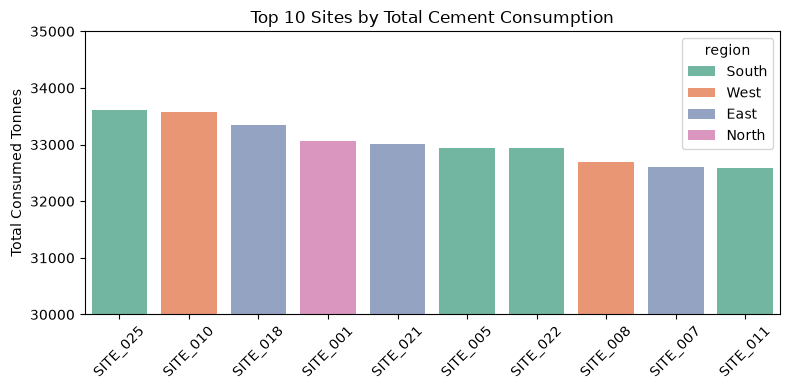

In [9]:
#Top 10 sites by total consumption

top_sites = kpi_summary.sort_values('total_consumed_tonnes', ascending=False).head(10)

plt.figure(figsize=(8, 4))
sns.barplot(x='site_id', y='total_consumed_tonnes', data=top_sites,
            hue='region', dodge=False, palette='Set2')
plt.title('Top 10 Sites by Total Cement Consumption')
plt.xticks(rotation=45)
plt.ylim(30000, 35000)
plt.ylabel('Total Consumed Tonnes')
plt.xlabel('')
plt.tight_layout()
plt.show()

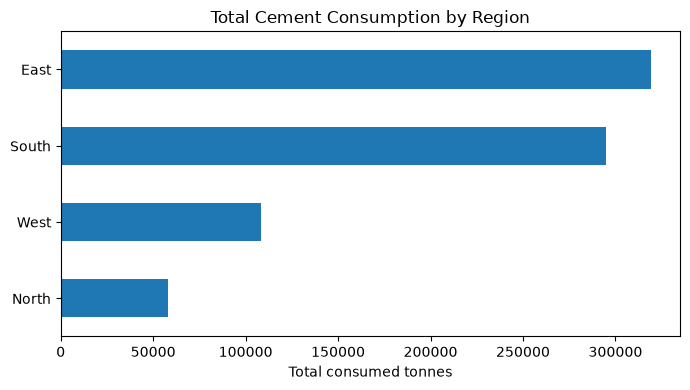

In [10]:
#Total consumption by region
region_con = df.groupby('region')['consumed_tonnes'].sum().sort_values()

region_con.plot(kind='barh', figsize=(7, 4), title='Total Cement Consumption by Region')
plt.xlabel('Total consumed tonnes')
plt.ylabel('')
plt.tight_layout()
plt.show()

## Extra EDA

In [11]:
### A. Regions: number of sites vs site size
region_summary = kpi_summary.groupby('region').agg(
    sites=('site_id', 'count'),
    total_consumed=('total_consumed_tonnes', 'sum'),
    avg_per_site=('total_consumed_tonnes', 'mean'),
).round(0).sort_values('total_consumed', ascending=False)

region_summary

,sites,total_consumed,avg_per_site
region,,,
East,12,318968.0,26581.0
South,11,294888.0,26808.0
West,4,108221.0,27055.0
North,3,57852.0,19284.0


### Demand over time

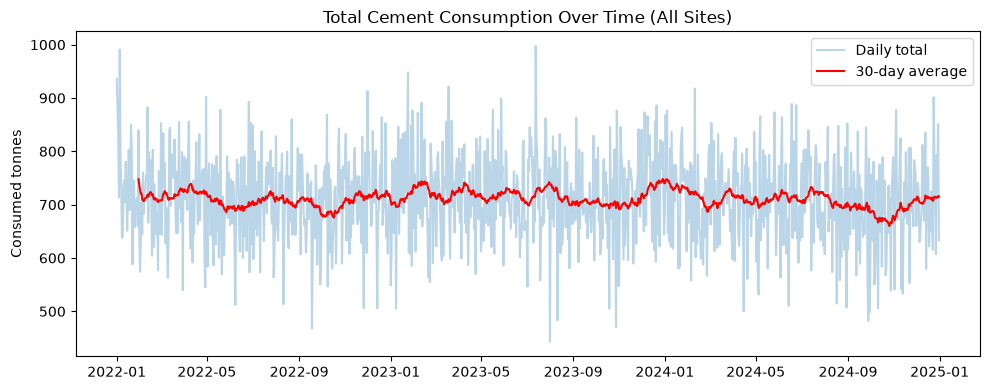

In [12]:


daily = df.groupby('date')['consumed_tonnes'].sum()

plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily, alpha=0.3, label='Daily total')
plt.plot(daily.index, daily.rolling(30).mean(), color='red', label='30-day average')
plt.title('Total Cement Consumption Over Time (All Sites)')
plt.ylabel('Consumed tonnes')
plt.legend()
plt.tight_layout()
plt.show()

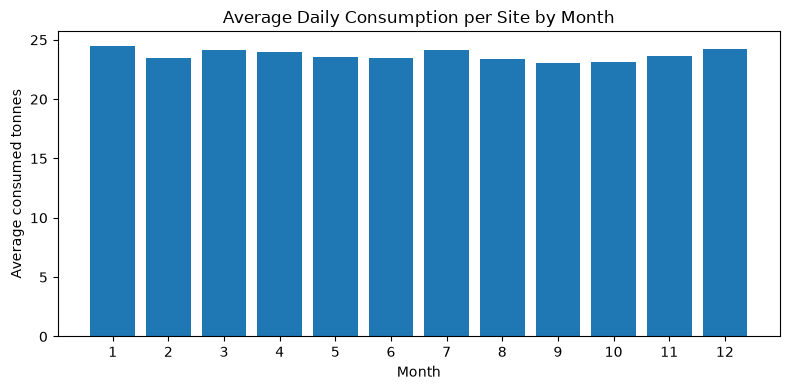

In [13]:
monthly = df.groupby(df['date'].dt.month)['consumed_tonnes'].mean()

plt.figure(figsize=(8, 4))
plt.bar(monthly.index, monthly)
plt.title('Average Daily Consumption per Site by Month')
plt.xlabel('Month')
plt.ylabel('Average consumed tonnes')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

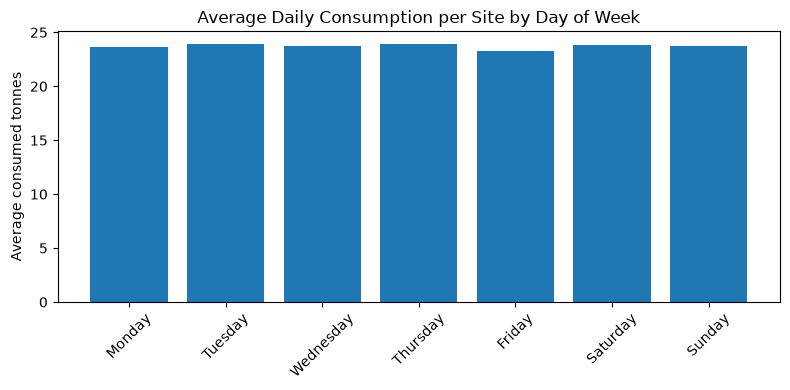

In [14]:
### Day of week

dow = df.groupby(df['date'].dt.day_name())['consumed_tonnes'].mean()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = dow.reindex(order)

plt.figure(figsize=(8, 4))
plt.bar(dow.index, dow)
plt.title('Average Daily Consumption per Site by Day of Week')
plt.ylabel('Average consumed tonnes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Planned pours vs actual consumption

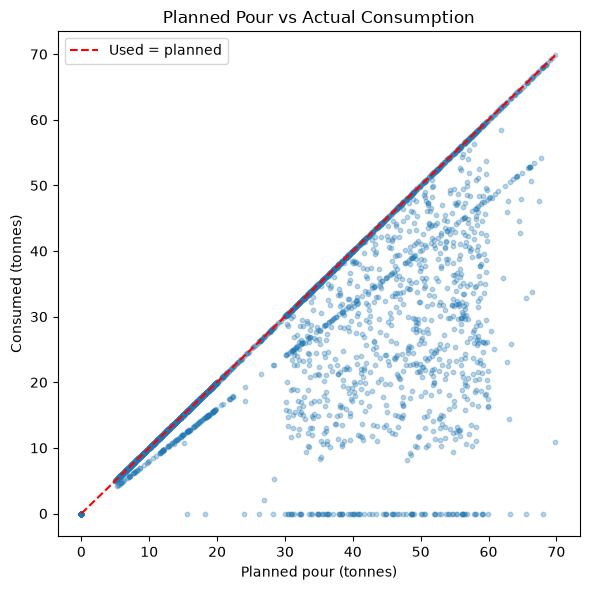

Correlation: 0.781


In [15]:


sample = df.sample(3000, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(sample['planned_pour_tonnes'], sample['consumed_tonnes'], alpha=0.3, s=10)
plt.plot([0, df['planned_pour_tonnes'].max()], [0, df['planned_pour_tonnes'].max()],
         color='red', linestyle='--', label='Used = planned')
plt.title('Planned Pour vs Actual Consumption')
plt.xlabel('Planned pour (tonnes)')
plt.ylabel('Consumed (tonnes)')
plt.legend()
plt.tight_layout()
plt.show()

print("Correlation:", round(df['planned_pour_tonnes'].corr(df['consumed_tonnes']), 3))

In [16]:
df['shortfall'] = df['consumed_tonnes'] < df['planned_pour_tonnes']

pd.crosstab(df['stockout'], df['shortfall'], normalize='index').round(3) * 100

shortfall,False,True
stockout,,
False,85.1,14.9
True,0.0,100.0


In [17]:
import numpy as np
df['pct_of_plan_used'] = df['consumed_tonnes'] / df['planned_pour_tonnes'].replace(0, np.nan) * 100

print("Days where full plan was used:",
      round((df['consumed_tonnes'] >= df['planned_pour_tonnes']).mean() * 100, 1), "%")

df['heavy_rain'] = df['rain_mm'] > 10
df.groupby(['stockout', 'heavy_rain'])['pct_of_plan_used'].mean().round(1)

Days where full plan was used: 60.3 %


stockout  heavy_rain
False     False         97.0
          True          80.1
True      False         61.1
          True          37.7
Name: pct_of_plan_used, dtype: float64

### Site behaviour

In [18]:
kpi_summary.groupby('behavior').agg(
    sites=('site_id', 'count'),
    avg_daily_consumed=('avg_daily_consumed', 'mean'),
    stockout_pct=('stockout_pct', 'mean'),
    overstocking_pct=('overstocking_pct', 'mean'),
    waste_risk_pct=('waste_risk_pct', 'mean'),
).round(1)

,sites,avg_daily_consumed,stockout_pct,overstocking_pct,waste_risk_pct
behavior,,,,,
aggressive,14,30.0,57.5,0.0,0.0
chaotic,7,26.8,9.6,22.2,6.4
conservative,9,11.5,0.0,98.7,4.6


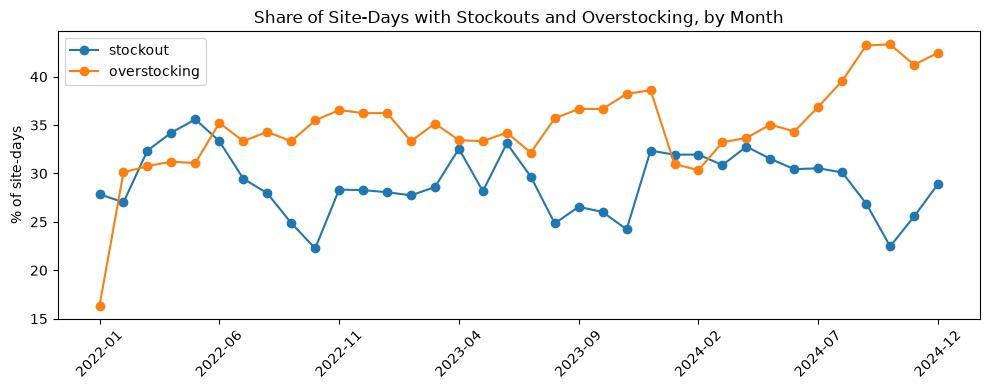

In [19]:
### Stockouts and overstocking over time

monthly_problems = df.groupby(df['date'].dt.to_period('M'))[['stockout', 'overstocking']].mean() * 100
monthly_problems.index = monthly_problems.index.astype(str)

monthly_problems.plot(figsize=(10, 4), marker='o')
plt.title('Share of Site-Days with Stockouts and Overstocking, by Month')
plt.ylabel('% of site-days')
plt.xlabel('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

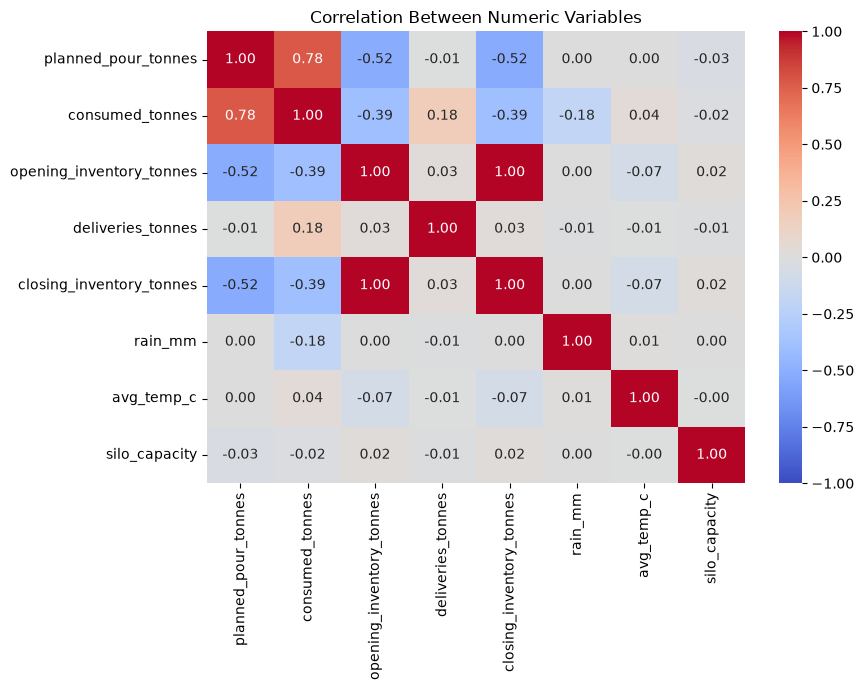

In [20]:
### Correlations between numeric variables

num_cols = ['planned_pour_tonnes', 'consumed_tonnes', 'opening_inventory_tonnes',
            'deliveries_tonnes', 'closing_inventory_tonnes', 'rain_mm',
            'avg_temp_c', 'silo_capacity']

plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Variables')
plt.tight_layout()
plt.show()